# AI4CM - Part 3
## Customer lifetime value (CLTV) - Olist Brazilian e-commerce


Repository update (November 2026): data paths now use the folders documented in `data/README.md`. Saved results come from the final course notebook. Raw datasets are obtained separately from their publishers. Parallel training in Part 3 is limited to one worker to reduce memory use. The numerical experiments and hyperparameter grids are otherwise retained. Some interpretations have been qualified where the original text overstated generalization or independence.

In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

from pathlib import Path

def find_repository_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "environment.yml").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Open the notebook from the repository root or its project subfolder.")

ROOT = find_repository_root()
DATA_DIR = ROOT / "data/olist"
if not (DATA_DIR / "olist_orders_dataset.csv").exists():
    raise FileNotFoundError("Missing Olist tables in data/olist; see data/README.md")


Using data folder: [local data folder]


## Task A - Data audit & quality

Olist is a relational dataset: 9 tables linked by keys (`order_id`, `customer_id`, `product_id`, `seller_id`, zip codes). We audit every table first, then keep only what CLTV needs.

In [2]:
# Load all 9 tables and build a one-glance audit (rows, cols, duplicates, missing).
# Date columns are parsed at load time so all later time-window logic is explicit.
files = {
    "orders":      "olist_orders_dataset.csv",
    "customers":   "olist_customers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "categories":  "product_category_name_translation.csv",
}
parse_dates = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}

tables = {}
for name, fn in files.items():
    tables[name] = pd.read_csv(DATA_DIR / fn, parse_dates=parse_dates.get(name, None))

audit = pd.DataFrame({
    name: {
        "rows": len(df),
        "cols": df.shape[1],
        "full_row_duplicates": int(df.duplicated().sum()),
        "cols_with_missing": int((df.isnull().sum() > 0).sum()),
        "total_missing_cells": int(df.isnull().sum().sum()),
    } for name, df in tables.items()
}).T
display(audit)

,rows,cols,full_row_duplicates,cols_with_missing,total_missing_cells
orders,99441,8,0,3,4908
customers,99441,5,0,0,0
order_items,112650,7,0,0,0
payments,103886,5,0,0,0
reviews,99224,7,0,2,145903
products,32951,9,0,8,2448
sellers,3095,4,0,0,0
geolocation,1000163,5,261831,0,0
categories,71,2,0,0,0


Audit findings.
- The dataset spans 9 tables; the ones relevant to CLTV are orders, customers, order_items and payments.
- There are no full-row duplicates anywhere except `geolocation` (about 262k repeated lat/long rows), which is irrelevant to CLTV, so we ignore that table.
- Missing values are concentrated and meaningful: `orders` lacks some delivery timestamps (orders not yet or never delivered), `reviews` lacks free-text comments (most customers leave none), and `products` lacks a category for 610 products. None of these blocks CLTV, which only needs who bought, when, and for how much.

In [3]:
# --- Relational integrity audit: key cardinalities and join traps ---
orders = tables["orders"].copy()
customers = tables["customers"].copy()
items = tables["order_items"].copy()
payments = tables["payments"].copy()
reviews = tables["reviews"].copy()
products = tables["products"].copy()
sellers = tables["sellers"].copy()

key_checks = pd.DataFrame([
    ["customers.customer_id", customers["customer_id"].nunique(), customers.duplicated("customer_id").sum()],
    ["customers.customer_unique_id", customers["customer_unique_id"].nunique(), customers.duplicated("customer_unique_id").sum()],
    ["orders.order_id", orders["order_id"].nunique(), orders.duplicated("order_id").sum()],
    ["orders.customer_id", orders["customer_id"].nunique(), orders.duplicated("customer_id").sum()],
    ["items.order_id + order_item_id", items[["order_id", "order_item_id"]].drop_duplicates().shape[0], items.duplicated(["order_id", "order_item_id"]).sum()],
    ["payments.order_id + payment_sequential", payments[["order_id", "payment_sequential"]].drop_duplicates().shape[0], payments.duplicated(["order_id", "payment_sequential"]).sum()],
    ["reviews.review_id", reviews["review_id"].nunique(), reviews.duplicated("review_id").sum()],
    ["reviews.order_id", reviews["order_id"].nunique(), reviews.duplicated("order_id").sum()],
    ["products.product_id", products["product_id"].nunique(), products.duplicated("product_id").sum()],
    ["sellers.seller_id", sellers["seller_id"].nunique(), sellers.duplicated("seller_id").sum()],
], columns=["key", "unique_keys", "duplicate_key_rows"])
display(key_checks)

items_per_order = items.groupby("order_id").size().rename("item_rows")
payments_per_order = payments.groupby("order_id").size().rename("payment_rows")
reviews_per_order = reviews.groupby("order_id").size().rename("review_rows")
join_risk = pd.concat([items_per_order, payments_per_order, reviews_per_order], axis=1).fillna(0).astype(int)
join_risk["item_x_payment_rows"] = join_risk["item_rows"] * join_risk["payment_rows"]
print("Relational coverage:")
print(f"  orders without items:    {(~orders['order_id'].isin(items['order_id'])).sum():,}")
print(f"  orders without payments: {(~orders['order_id'].isin(payments['order_id'])).sum():,}")
print(f"  orders without reviews:  {(~orders['order_id'].isin(reviews['order_id'])).sum():,}")
print(f"  item product_ids missing in products: {(~items['product_id'].isin(products['product_id'])).sum():,}")
print(f"  item seller_ids missing in sellers:   {(~items['seller_id'].isin(sellers['seller_id'])).sum():,}")
print("\nMany-to-many join risk:")
print(f"  orders with >1 item row:    {(join_risk['item_rows'] > 1).sum():,} (max {join_risk['item_rows'].max()})")
print(f"  orders with >1 payment row: {(join_risk['payment_rows'] > 1).sum():,} (max {join_risk['payment_rows'].max()})")
print(f"  orders with >1 review row:  {(join_risk['review_rows'] > 1).sum():,} (max {join_risk['review_rows'].max()})")
print(f"  direct item x payment join would create {join_risk['item_x_payment_rows'].sum():,} rows vs {len(items):,} item rows")
print(f"  orders where direct item-payment join would duplicate payment value: {(join_risk['item_x_payment_rows'] > join_risk['item_rows']).sum():,}")


,key,unique_keys,duplicate_key_rows
0,customers.customer_id,99441,0
1,customers.customer_unique_id,96096,3345
2,orders.order_id,99441,0
3,orders.customer_id,99441,0
4,items.order_id + order_item_id,112650,0
5,payments.order_id + payment_sequential,103886,0
6,reviews.review_id,98410,814
7,reviews.order_id,98673,551
8,products.product_id,32951,0
9,sellers.seller_id,3095,0


Relational coverage:
  orders without items:    775
  orders without payments: 1
  orders without reviews:  768
  item product_ids missing in products: 0
  item seller_ids missing in sellers:   0

Many-to-many join risk:
  orders with >1 item row:    9,803 (max 21)
  orders with >1 payment row: 2,961 (max 29)
  orders with >1 review row:  547 (max 3)
  direct item x payment join would create 117,601 rows vs 112,650 item rows
  orders where direct item-payment join would duplicate payment value: 2,936


Relational audit findings.
- `customer_unique_id` is the real person key; `customer_id` is unique per order. This is the most important Olist trap.
- `order_items`, `payments`, and `reviews` are not all one-row-per-order. A direct merge between item rows and payment rows would create extra rows and duplicate value. Therefore revenue must be aggregated at order level before joining.
- Reviews also have repeated `review_id` and repeated `order_id`, so review signals are useful only after aggregation and only if we respect the calibration cutoff.


Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Time span: 2016-09-04 21:15:19  ->  2018-10-17 17:30:18
order_id unique: 99,441  |  customer_id unique: 99,441


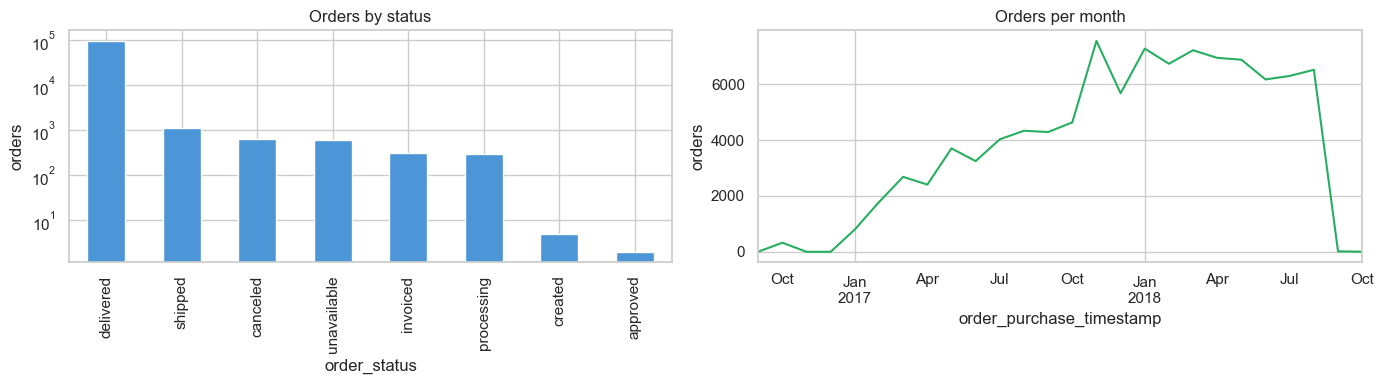

In [4]:
# --- ORDERS: status & time span (which transactions are valid for CLTV?) ---
orders = tables["orders"].copy()
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])

print("Order status distribution:")
print(orders["order_status"].value_counts().to_string())
print(f"\nTime span: {orders['order_purchase_timestamp'].min()}  ->  {orders['order_purchase_timestamp'].max()}")
print(f"order_id unique: {orders['order_id'].nunique():,}  |  customer_id unique: {orders['customer_id'].nunique():,}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
orders["order_status"].value_counts().plot(kind="bar", ax=ax[0], color="#4C96D7")
ax[0].set_title("Orders by status"); ax[0].set_ylabel("orders"); ax[0].set_yscale("log")
orders.set_index("order_purchase_timestamp").resample("ME").size().plot(ax=ax[1], color="#27AE60")
ax[1].set_title("Orders per month"); ax[1].set_ylabel("orders")
plt.tight_layout(); plt.show()

Orders.
- 96,478 of 99,441 orders (97%) are `delivered`, i.e. genuine completed sales. The rest are `shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created` or `approved`. For a revenue-based CLTV we keep only `delivered` orders (the others are not realised revenue, or are cancellations).
- `order_id` and `customer_id` are both unique (99,441), so `customer_id` is a per-order key, not a person. This is the classic Olist trap, addressed in the next cell.
- Activity is negligible in 2016, ramps up through 2017, and runs to October 2018, so the usable window is roughly January 2017 to August 2018.

In [5]:
# --- CUSTOMERS: the real customer key, and the repeat-purchase reality ---
customers = tables["customers"].copy()
print(f"customer_id unique:        {customers['customer_id'].nunique():,}  (one per order)")
print(f"customer_unique_id unique: {customers['customer_unique_id'].nunique():,}  (real people)")

# Orders per REAL customer (delivered only)
deliv = orders[orders["order_status"] == "delivered"].merge(
    customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
orders_per_cust = deliv.groupby("customer_unique_id")["order_id"].nunique()
dist = orders_per_cust.value_counts().sort_index()
print("\nOrders per real customer:")
print(dist.head(8).to_string())
repeat = (orders_per_cust >= 2).sum()
print(f"\nRepeat customers (>=2 orders): {repeat:,} ({repeat/len(orders_per_cust)*100:.2f}%)")
print(f"One-time customers:            {(orders_per_cust==1).sum():,} ({(orders_per_cust==1).mean()*100:.2f}%)")

customer_id unique:        99,441  (one per order)
customer_unique_id unique: 96,096  (real people)

Orders per real customer:
order_id
1    90557
2     2573
3      181
4       28
5        9
6        5
7        3
9        1

Repeat customers (>=2 orders): 2,801 (3.00%)
One-time customers:            90,557 (97.00%)


The customer key and the retention reality (important).
- We must aggregate on `customer_unique_id` (96,096 real people), not `customer_id` (99,441 order-level keys). Using the wrong key would make every customer look like a one-timer.
- Only about 3.0% of customers ever place a 2nd order; about 97.0% buy once (delivered orders). This is the central fact for the modelling: Olist has very low repeat purchasing, so the BTYD models (which learn from repeat behaviour) will see mostly frequency = 0 customers and lean heavily on population-level priors. We model it faithfully but flag this limitation throughout.

In [6]:
# --- REVENUE definition: order_items (price+freight) vs payments (payment_value) ---
items = tables["order_items"].copy()
payments = tables["payments"].copy()

order_rev_items = (items.assign(rev=items["price"] + items["freight_value"])
                        .groupby("order_id")["rev"].sum())
order_rev_pay = payments.groupby("order_id")["payment_value"].sum()
cmp = pd.concat([order_rev_items.rename("items_price_freight"),
                 order_rev_pay.rename("payment_value")], axis=1)
print("Orders covered - items:", items["order_id"].nunique(),
      "| payments:", payments["order_id"].nunique(), "| orders:", orders["order_id"].nunique())
print("Correlation between the two revenue definitions:",
      round(cmp.dropna().corr().iloc[0, 1], 4))
display(cmp.describe().loc[["mean", "50%", "min", "max"]].round(2))

# Outliers in QUANTITIES (Task A): Olist has no explicit Quantity column -> the analogue is
# the number of item lines per order.
items_per_order = items.groupby("order_id").size()
print(f"\nItems per order ('quantity'): median {items_per_order.median():.0f}, "
      f"99th pct {items_per_order.quantile(0.99):.0f}, max {items_per_order.max()} "
      f"({(items_per_order > 10).sum()} orders with >10 items)")

Orders covered - items: 98666 | payments: 99440 | orders: 99441
Correlation between the two revenue definitions: 1.0


,items_price_freight,payment_value
mean,160.58,160.99
50%,105.29,105.29
min,9.59,0.00
max,"13,664.08","13,664.08"



Items per order ('quantity'): median 1, 99th pct 3, max 21 (17 orders with >10 items)


Revenue definition.
- `price + freight_value` (from `order_items`) and `payment_value` (from `payments`) are essentially identical (correlation about 1.00, same mean about R\$161, same median R\$105), so either is valid.
- We use `price + freight_value` as the order value, since it is available for every item row. (775 orders have no item rows, mostly non-delivered, and are dropped by the `delivered` filter anyway.)
- Outliers in quantities (Task A). Olist has no explicit `Quantity` column; the analogue is the number of item lines per order, with median 1, 99th percentile 3 and max 21 (only 17 orders with more than 10 items). Since order value sums `price + freight` over those items, a large basket simply shows up as high revenue, so it is already bounded by the 99th-percentile revenue winsorisation in the next cell. A separate cap on item count is therefore unnecessary; we still check the distribution explicitly rather than leave it unverified.

Important business assumption: GMV, not Olist's own revenue. Olist is a marketplace: the `price` is paid to the third-party seller and `freight` to the carrier, and Olist itself earns only a commission (take-rate), which is not present in this dataset. So `price + freight` is Gross Merchandise Value (GMV), not Olist's revenue or profit. With no take-rate available, GMV is the only technical proxy for customer value, so every "CLTV / value" figure in this notebook is a predicted GMV (Olist's actual revenue is roughly take-rate x GMV). This needs to be stated explicitly to the Head of Marketing / CFO before any budgeting decision.

In [7]:
# --- CLEANING PIPELINE: build the clean transactional table for CLTV ---
def build_transactions(orders, customers, items):
    # 1. keep only realised sales
    o = orders[orders["order_status"] == "delivered"].copy()
    # 2. attach the REAL customer id
    o = o.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
    # 3. order revenue = sum(price + freight) across the order's items
    rev = (items.assign(rev=items["price"] + items["freight_value"])
                .groupby("order_id")["rev"].sum().rename("revenue"))
    o = o.merge(rev, on="order_id", how="inner")            # inner: drop orders without items
    # 4. transaction grain: one row per (customer, order, date)
    tx = o[["customer_unique_id", "order_id", "order_purchase_timestamp", "revenue"]].copy()
    tx["date"] = tx["order_purchase_timestamp"].dt.normalize()
    return tx

tx = build_transactions(orders, customers, items)
print(f"Transactions (all delivered):       {len(tx):,} (customers: {tx['customer_unique_id'].nunique():,})")

# 5. ANOMALY - the 2016 dormant stub (Task A "investigate data anomalies").
pre_stub = tx[tx["date"] < "2017-01-01"].copy()
post_stub = tx[tx["date"] >= "2017-01-01"].copy()
stub_returners = len(set(pre_stub["customer_unique_id"]) & set(post_stub["customer_unique_id"]))
print("2016 stub audit:")
print(pre_stub.set_index("date").resample("ME").size().rename("delivered_orders").to_string())
print(f"  pre-2017 delivered transactions: {len(pre_stub):,} | customers: {pre_stub['customer_unique_id'].nunique():,} | customers returning after 2017-01-01: {stub_returners:,}")

tx = post_stub.copy()
print(f"Dropped {len(pre_stub):,} transactions from the dormant 2016 stub -> analysis window starts 2017-01-01")

# 6. manage EXTREME outliers in order value (Task A): winsorise revenue at the 99th percentile.
#    The cap is LEARNED ONLY on the calibration-period transactions and then applied to all,
#    so the future holdout / test data never informs the cleaning threshold (leakage-free).
tx["revenue_raw"] = tx["revenue"]
HOLDOUT_DAYS = 90
cal_cutoff = tx["date"].max() - pd.Timedelta(days=HOLDOUT_DAYS)
cap = tx.loc[tx["date"] <= cal_cutoff, "revenue_raw"].quantile(0.99)
excess_value = (tx["revenue_raw"] - tx["revenue_raw"].clip(upper=cap)).sum()
n_out = int((tx["revenue_raw"] > cap).sum())
raw_total = tx["revenue_raw"].sum()
tx["revenue"] = tx["revenue_raw"].clip(upper=cap)
print(f"Revenue 99th-pct cap (learned on calibration period only) = R${cap:,.2f}")
print(f"  extreme orders winsorised: {n_out:,} ({n_out/len(tx):.2%})")
print(f"  GMV reduced by cap: R${excess_value:,.2f} ({excess_value/raw_total:.2%} of uncapped GMV)")
print(f"Revenue after cap: min R${tx['revenue'].min():.2f}, median R${tx['revenue'].median():.2f}, max R${tx['revenue'].max():.2f}")
print(f"\nFinal clean transactions: {len(tx):,} | unique customers: {tx['customer_unique_id'].nunique():,} | "
      f"date range {tx['date'].min().date()} -> {tx['date'].max().date()}")
display(tx.head())

Transactions (all delivered):       96,478 (customers: 93,358)
2016 stub audit:
date
2016-09-30      1
2016-10-31    265
2016-11-30      0
2016-12-31      1
Freq: ME
  pre-2017 delivered transactions: 267 | customers: 264 | customers returning after 2017-01-01: 10
Dropped 267 transactions from the dormant 2016 stub -> analysis window starts 2017-01-01
Revenue 99th-pct cap (learned on calibration period only) = R$1,052.11
  extreme orders winsorised: 966 (1.00%)
  GMV reduced by cap: R$587,974.54 (3.82% of uncapped GMV)
Revenue after cap: min R$9.59, median R$105.28, max R$1052.11



Final clean transactions: 96,211 | unique customers: 93,104 | date range 2017-01-05 -> 2018-08-29


,customer_unique_id,order_id,order_purchase_timestamp,revenue,date,revenue_raw
0,7c396fd4830fd04220f754e42b4e5bff,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,38.71,2017-10-02,38.71
1,af07308b275d755c9edb36a90c618231,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,141.46,2018-07-24,141.46
2,3a653a41f6f9fc3d2a113cf8398680e8,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,179.12,2018-08-08,179.12
3,7c142cf63193a1473d2e66489a9ae977,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,72.20,2017-11-18,72.20
4,72632f0f9dd73dfee390c9b22eb56dd6,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,28.62,2018-02-13,28.62


Cleaning pipeline (Task A complete).
We turned the relational Olist data into a single transactional table `(customer_unique_id, order_id, date, revenue)` with explicit, documented choices:
1. Filter invalid transactions: keep only `delivered` orders (cancellations and unavailable orders removed).
2. Correct customer key: `customer_unique_id`.
3. Revenue: `price + freight` per order, interpreted as GMV rather than Olist net revenue.
4. Inner-join with order items after the status filter; this protects the transaction grain and avoids item/payment many-to-many duplication.
5. Data anomaly: the 2016 dormant stub is removed. The audit above shows it is tiny, operationally discontinuous, and only a handful of those customers return after 2017. Keeping it would inflate tenure `T` and weaken the BG/NBD constant-rate assumption.
6. Outlier management: order revenue is winsorised at the calibration-period 99th percentile. The notebook now prints both the number of capped orders and the GMV impact, so the cap is transparent rather than hidden.

Known data limitations. The figures are GMV, not Olist profit; late 2018 is right-truncated because delivered-only orders exclude transactions not yet delivered; same-day orders collapse under daily BTYD frequency; and review information must be cutoff-safe before it is used as an ML feature.

## Task B - Exploratory data analysis & RFM feature engineering

We explore the data and engineer the RFM features used by the models in Task C.

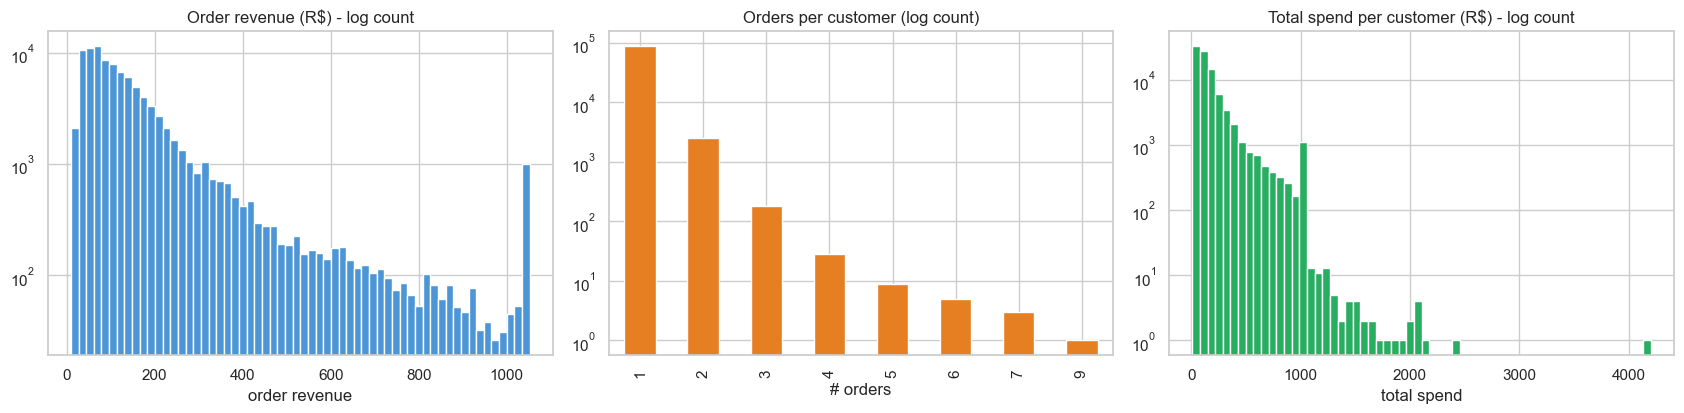

Customer spend: mean R$158.80 | median R$107.78 | top-1% threshold R$1052.11


In [8]:
# --- EDA: distributions of order value, spend, and purchase frequency ---
cust_orders = tx.groupby("customer_unique_id").agg(
    n_orders=("order_id", "nunique"), total_spend=("revenue", "sum")).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].hist(tx["revenue"], bins=60, color="#4C96D7"); ax[0].set_yscale("log")
ax[0].set_title("Order revenue (R$) - log count"); ax[0].set_xlabel("order revenue")
cust_orders["n_orders"].value_counts().sort_index().head(8).plot(
    kind="bar", ax=ax[1], color="#E67E22"); ax[1].set_yscale("log")
ax[1].set_title("Orders per customer (log count)"); ax[1].set_xlabel("# orders")
ax[2].hist(cust_orders["total_spend"], bins=60, color="#27AE60"); ax[2].set_yscale("log")
ax[2].set_title("Total spend per customer (R$) - log count"); ax[2].set_xlabel("total spend")
plt.tight_layout(); plt.show()

print("Customer spend: mean R${:.2f} | median R${:.2f} | top-1% threshold R${:.2f}".format(
    cust_orders["total_spend"].mean(), cust_orders["total_spend"].median(),
    cust_orders["total_spend"].quantile(0.99)))

EDA.
- Order revenue is right-skewed (median about R\$105), typical for retail; the winsorising tamed the extreme tail.
- Orders per customer are overwhelmingly 1 (note the log scale): the repeat tail is tiny, which makes the retention problem visual.
- Total spend per customer is about equal to a single order's revenue for most people (since most buy once); only the small repeat segment accumulates more. So Olist's value is concentrated in acquisition, and growing the thin repeat segment is the main CLTV lever.

In [9]:
# --- RFM Feature Engineering: customer-level Recency, Frequency, Monetary, T ---
from lifetimes.utils import summary_data_from_transaction_data

observation_end = tx["date"].max()
rfm = summary_data_from_transaction_data(
    transactions=tx,
    customer_id_col="customer_unique_id",
    datetime_col="date",
    monetary_value_col="revenue",
    observation_period_end=observation_end,
    freq="D",
)
print("RFM (lifetimes) customer-level table:", rfm.shape)
display(rfm.describe().round(2))
print("Customers with >=1 repeat purchase (frequency > 0):", int((rfm["frequency"] > 0).sum()))
display(rfm.head())

RFM (lifetimes) customer-level table: (93104, 4)


,frequency,recency,T,monetary_value
count,"93,104.00","93,104.00","93,104.00","93,104.00"
mean,0.02,2.61,238.85,3.22
std,0.18,24.59,151.42,30.96
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,116.00,0.00
50%,0.00,0.00,221.00,0.00
75%,0.00,0.00,349.00,0.00
max,14.00,583.00,601.00,"2,104.21"


Customers with >=1 repeat purchase (frequency > 0): 2005


,frequency,recency,T,monetary_value
customer_unique_id,,,,
0000366f3b9a7992bf8c76cfdf3221e2,0.00,0.00,111.00,0.00
0000b849f77a49e4a4ce2b2a4ca5be3f,0.00,0.00,114.00,0.00
0000f46a3911fa3c0805444483337064,0.00,0.00,537.00,0.00
0000f6ccb0745a6a4b88665a16c9f078,0.00,0.00,321.00,0.00
0004aac84e0df4da2b147fca70cf8255,0.00,0.00,288.00,0.00


RFM table (Task B complete).
`summary_data_from_transaction_data` collapses the transactions into one row per customer with the four BTYD quantities:
- frequency = number of repeat purchases (so a one-time buyer has frequency 0); here the mean is about 0.02 and about 97.8% of customers have frequency 0 (91,099 of 93,104).
- recency = the age of the customer at their last purchase (days between first and last order).
- T = tenure/age = days between the first purchase and the observation end (how long we could have observed them).
- monetary_value = average revenue of the repeat transactions (0 for one-time buyers, so Gamma-Gamma uses only frequency > 0 customers). Because the table is built at daily granularity (`freq='D'`), a "transaction" is a purchase-day, so multiple orders on the same day are summed and `monetary_value` is the average spend per purchase-day rather than strictly per order (this also explains a `monetary_value` slightly above the per-order cap for a few same-day double orders).

The about 2,005 customers with frequency > 0 are the only ones carrying a repeat-purchase signal; the BTYD models in Task C must extract value from this thin slice plus the population priors. (This is fewer than the 2,801 customers with at least 2 orders in the raw audit, for two reasons: in the daily RFM, repeat orders on the same calendar day collapse into one purchase, and the 2016 stub was trimmed.)

RFM distribution checks:
  T range: 0 -> 601 days | median 221
  Frequency counts (first bins):
frequency
0.00     91099
1.00      1855
2.00       119
3.00        17
4.00         6
5.00         5
6.00         2
14.00        1
  Repeat-customer recency: median 80 days | 75th pct 186


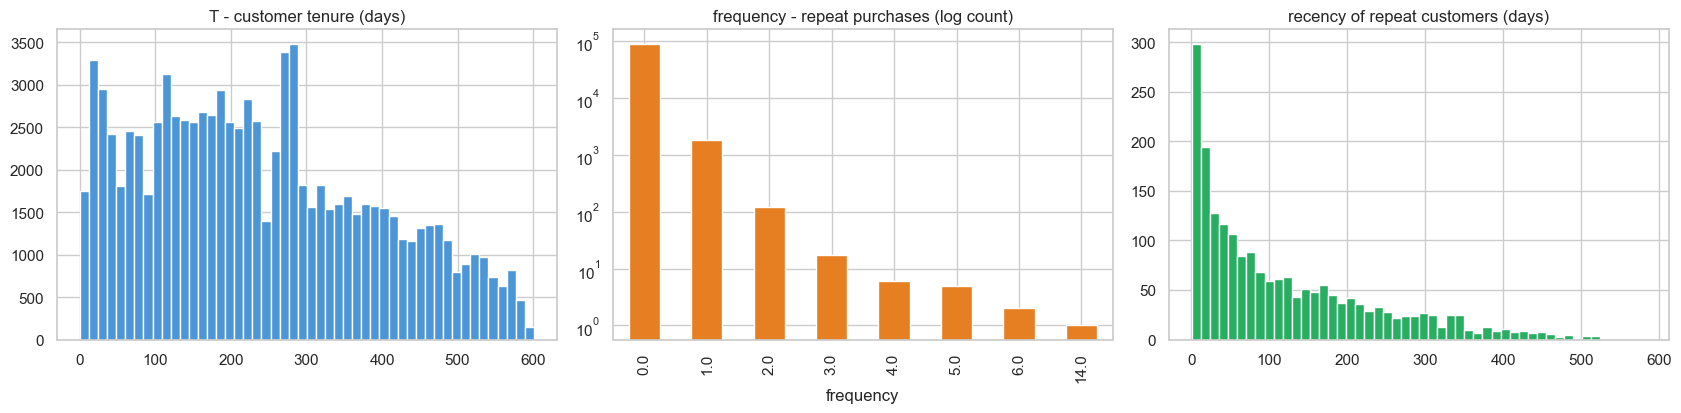

In [10]:
# Distribution of the RFM features (the inputs to the BTYD models)
print("RFM distribution checks:")
print(f"  T range: {rfm['T'].min():.0f} -> {rfm['T'].max():.0f} days | median {rfm['T'].median():.0f}")
print("  Frequency counts (first bins):")
print(rfm["frequency"].value_counts().sort_index().head(8).to_string())
repeat_recency = rfm.loc[rfm["frequency"] > 0, "recency"]
print(f"  Repeat-customer recency: median {repeat_recency.median():.0f} days | 75th pct {repeat_recency.quantile(0.75):.0f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].hist(rfm["T"], bins=50, color="#4C96D7"); ax[0].set_title("T - customer tenure (days)")
rfm["frequency"].value_counts().sort_index().head(8).plot(kind="bar", ax=ax[1], color="#E67E22")
ax[1].set_yscale("log"); ax[1].set_title("frequency - repeat purchases (log count)")
ax[2].hist(rfm.loc[rfm["frequency"] > 0, "recency"], bins=50, color="#27AE60")
ax[2].set_title("recency of repeat customers (days)")
plt.tight_layout(); plt.show()


RFM distributions.
- T (tenure) spreads fairly uniformly up to about 600 days, since customers were acquired across the whole window.
- frequency is about 0 for almost everyone (log scale); the repeat counts decay fast.
- recency (for repeat buyers only) shows that the second purchase usually comes within a few hundred days.

This `rfm` table is the input the BG/NBD model (frequency, recency, T) and the Gamma-Gamma model (frequency, monetary_value) need, built next in Task C.


## Task C - Modeling & evaluation

We estimate CLTV two ways and compare them:
1. Probabilistic (BTYD): BG/NBD (future purchases plus P(alive)) and Gamma-Gamma (monetary value), giving a 90-day CLTV.
2. Machine learning: a regressor predicting each customer's holdout-period revenue from their calibration features.

Validation design. We split time into a calibration period and a 90-day holdout, matching the 90-day CLTV horizon. To compare the two approaches fairly and out-of-sample, we also split the customers 80/20: both model families are fit on the train customers' calibration data and scored on the test customers' actual holdout revenue.

In [11]:
from lifetimes.utils import calibration_and_holdout_data
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.plotting import plot_calibration_purchases_vs_holdout_purchases
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
RANDOM_STATE = 42

HOLDOUT_DAYS = 90
obs_end = tx["date"].max()
cal_end = obs_end - pd.Timedelta(days=HOLDOUT_DAYS)
ch = calibration_and_holdout_data(
    tx, "customer_unique_id", "date",
    calibration_period_end=cal_end, observation_period_end=obs_end,
    monetary_value_col="revenue", freq="D")

print(f"Calibration: {tx['date'].min().date()} -> {cal_end.date()}   |   Holdout: next {HOLDOUT_DAYS} days -> {obs_end.date()}")
print(f"Calibration customers: {len(ch):,}")
print(f"  with >=1 repeat in calibration (freq_cal>0): {(ch['frequency_cal']>0).sum():,}")
print(f"  who purchased again in the holdout       : {(ch['frequency_holdout']>0).sum():,}")

# --- Enrich the ML feature set with extra CALIBRATION-period signals (orders <= cal_end only).
#     This rescues the ML from "monetary blindness": the lifetimes monetary_value is 0 for the
#     97% one-time buyers, so without this a R$10 and a R$5,000 first order look identical.
cal_tx = tx[tx["date"] <= cal_end].sort_values("date")
g = cal_tx.groupby("customer_unique_id")
feat = pd.DataFrame({
    "first_order_rev": g["revenue"].first(),
    "total_cal_rev":   g["revenue"].sum(),
    "n_cal_orders":    g["order_id"].nunique(),
})

# Cross-table signals the parametric BTYD cannot use.
# Review leakage guard: a calibration order's review may be written after cal_end, so use only
# reviews created by the calibration cutoff. This is small but important for a strict evaluation.
reviews_cutoff_safe = tables["reviews"].copy()
late_review_mask = (reviews_cutoff_safe["order_id"].isin(set(cal_tx["order_id"]))) & (reviews_cutoff_safe["review_creation_date"] > cal_end)
late_review_rows = int(late_review_mask.sum())
review_sc = (reviews_cutoff_safe.loc[reviews_cutoff_safe["review_creation_date"] <= cal_end]
             .groupby("order_id")["review_score"].mean())

cc_orders = set(tables["payments"].loc[tables["payments"]["payment_type"] == "credit_card", "order_id"])
cat_of_ord = (tables["order_items"].merge(tables["products"][["product_id", "product_category_name"]], on="product_id")
                                .groupby("order_id")["product_category_name"].first())
cal_o = cal_tx.merge(review_sc, on="order_id", how="left").merge(cat_of_ord, on="order_id", how="left")
cal_o["is_cc"] = cal_o["order_id"].isin(cc_orders).astype(int)
feat["avg_review_score"] = cal_o.groupby("customer_unique_id")["review_score"].mean()
feat["pct_credit_card"]  = cal_o.groupby("customer_unique_id")["is_cc"].mean()
feat["n_categories"]     = cal_o.groupby("customer_unique_id")["product_category_name"].nunique()

ch = ch.join(feat)
# Deterministic zero fills: absent order-derived counts/values mean no calibration activity in that feature.
for col in ["first_order_rev", "total_cal_rev", "n_cal_orders", "pct_credit_card", "n_categories"]:
    ch[col] = ch[col].fillna(0)

# Stratify on whether the customer repeated in calibration, so the precious ~2% repeat
# segment is split proportionally (a purely random split could over/under-sample it).
train_ch, test_ch = train_test_split(
    ch, test_size=0.2, random_state=RANDOM_STATE, stratify=(ch["frequency_cal"] > 0))

# Train-only imputation for the review feature. This avoids even a small feature-distribution leak.
review_median = train_ch["avg_review_score"].median()
train_ch = train_ch.copy()
test_ch = test_ch.copy()
train_ch["avg_review_score"] = train_ch["avg_review_score"].fillna(review_median)
test_ch["avg_review_score"] = test_ch["avg_review_score"].fillna(review_median)

print("Enriched ML features added:", list(feat.columns))
print(f"Review leakage guard: {late_review_rows:,} calibration-order review rows were written after cal_end and excluded from avg_review_score")
print(f"Review median used for imputation (learned on train only): {review_median:.2f}")
print(f"Train customers: {len(train_ch):,} | Test customers: {len(test_ch):,}")
print(f"  repeaters (freq_cal>0) - train: {(train_ch['frequency_cal']>0).mean()*100:.2f}% | "
      f"test: {(test_ch['frequency_cal']>0).mean()*100:.2f}%  (stratified)")

Calibration: 2017-01-05 -> 2018-05-31   |   Holdout: next 90 days -> 2018-08-29
Calibration customers: 75,132
  with >=1 repeat in calibration (freq_cal>0): 1,493
  who purchased again in the holdout       : 418


Enriched ML features added: ['first_order_rev', 'total_cal_rev', 'n_cal_orders', 'avg_review_score', 'pct_credit_card', 'n_categories']
Review leakage guard: 2,335 calibration-order review rows were written after cal_end and excluded from avg_review_score
Review median used for imputation (learned on train only): 5.00
Train customers: 60,105 | Test customers: 15,027
  repeaters (freq_cal>0) - train: 1.99% | test: 1.99%  (stratified)


The split. The calibration window runs to 2018-05-31 and the holdout is the final 90 days, matching the CLTV horizon. Only a few hundred calibration customers repurchase in the holdout, so the target is heavily zero-inflated. The 80/20 customer split is stratified on `frequency_cal > 0` so the thin repeat segment appears in equal proportion in train and test.

Leakage control. Extra ML features use only information observable by `cal_end`. In particular, review scores are filtered by `review_creation_date <= cal_end`; reviews written later are excluded. Missing review score is imputed with the training-set median only. This is a small technical detail, but it matters because the model is forecasting future value from calibration-period information.

       coef  se(coef)  lower 95% bound  upper 95% bound
r      0.02      0.00             0.01             0.02
alpha 74.92      9.61            56.08            93.76
a      0.33      0.06             0.21             0.46
b      0.07      0.01             0.04             0.10


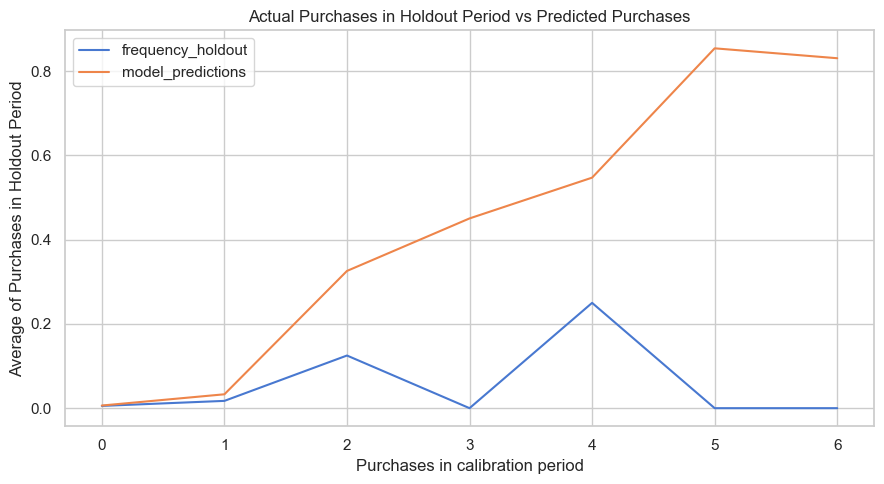

In [12]:
# --- C1. BG/NBD: expected future purchases & P(alive) ---
bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(train_ch["frequency_cal"], train_ch["recency_cal"], train_ch["T_cal"])
print(bgf.summary)

plot_calibration_purchases_vs_holdout_purchases(bgf, train_ch, n=7, figsize=(9, 5))
plt.tight_layout(); plt.show()

BG/NBD fit. The model converges (small standard errors). The calibration-vs-holdout plot groups customers by their number of calibration purchases and overlays the model's predicted average holdout purchases against the actual ones: the two lines track closely for the populated low-frequency bins, so the model is well-calibrated where the data lives; the high-frequency bins are noisy simply because almost no Olist customer reaches them.

In [13]:
# Out-of-sample validation: predicted vs actual HOLDOUT purchase count (test customers)
pred_freq = bgf.predict(test_ch["duration_holdout"], test_ch["frequency_cal"],
                        test_ch["recency_cal"], test_ch["T_cal"])
print("BG/NBD holdout purchase-count (test set):")
print(f"  MAE  = {mean_absolute_error(test_ch['frequency_holdout'], pred_freq):.4f}")
print(f"  RMSE = {np.sqrt(mean_squared_error(test_ch['frequency_holdout'], pred_freq)):.4f}")

# Penalizer sensitivity (addressing "why 0.001?"): holdout RMSE is flat across penalizers,
# so the light default is fine and the result is not a "magic number".
print("\nBG/NBD penalizer sensitivity (holdout-frequency RMSE):")
for pen in [0.0, 0.001, 0.01, 0.1]:
    _b = BetaGeoFitter(penalizer_coef=pen).fit(train_ch["frequency_cal"], train_ch["recency_cal"], train_ch["T_cal"])
    _p = _b.predict(test_ch["duration_holdout"], test_ch["frequency_cal"], test_ch["recency_cal"], test_ch["T_cal"])
    print(f"  penalizer={pen:<5} -> RMSE {np.sqrt(mean_squared_error(test_ch['frequency_holdout'], _p)):.4f}")

BG/NBD holdout purchase-count (test set):
  MAE  = 0.0126
  RMSE = 0.0774

BG/NBD penalizer sensitivity (holdout-frequency RMSE):


  penalizer=0.0   -> RMSE 0.0769


  penalizer=0.001 -> RMSE 0.0774


  penalizer=0.01  -> RMSE 0.0781


  penalizer=0.1   -> RMSE 0.0789


The errors are very small in absolute terms because the actual holdout purchase count is about 0 for almost everyone, and the model correctly predicts a low expected number of purchases. The value is in ranking who is more likely to buy, not in large count predictions. The penalizer sensitivity check above shows the holdout RMSE is essentially flat across `penalizer_coef` in {0, 0.001, 0.01, 0.1}, so 0.001 is a safe light default rather than a tuned magic number. (For the Gamma-Gamma, by contrast, the penalizer is not free: 0.001 is needed to keep the shape parameter q > 1, see the assumptions check.)

In [14]:
# --- C2. Gamma-Gamma: monetary value (check the assumptions first) ---
gg_train = train_ch[(train_ch["frequency_cal"] > 0) & (train_ch["monetary_value_cal"] > 0)]
corr_fm = gg_train["frequency_cal"].corr(gg_train["monetary_value_cal"])

ggf = GammaGammaFitter(penalizer_coef=0.001)
ggf.fit(gg_train["frequency_cal"], gg_train["monetary_value_cal"])
p, q, v = ggf._unload_params("p", "q", "v")
print(f"Assumption 1 - frequency vs monetary correlation: {corr_fm:.4f}  (want ~0)")
print(f"Assumption 2 - shape parameter q = {q:.3f}  (must be > 1 for a finite, positive mean)")
print(f"\nGamma-Gamma fitted on {len(gg_train):,} repeat customers")
print("q vs penalizer (shows q>1 is the natural fit, NOT forced by the penalizer):")
for pen in [0.0, 0.001, 0.01]:
    _q = GammaGammaFitter(penalizer_coef=pen).fit(gg_train["frequency_cal"], gg_train["monetary_value_cal"])._unload_params("p", "q", "v")[1]
    print(f"  penalizer={pen:<6} -> q={_q:.3f}")
print()
print(ggf.summary)

Assumption 1 - frequency vs monetary correlation: 0.0143  (want ~0)
Assumption 2 - shape parameter q = 1.367  (must be > 1 for a finite, positive mean)

Gamma-Gamma fitted on 1,194 repeat customers
q vs penalizer (shows q>1 is the natural fit, NOT forced by the penalizer):
  penalizer=0.0    -> q=3.001
  penalizer=0.001  -> q=1.367
  penalizer=0.01   -> q=0.500

   coef  se(coef)  lower 95% bound  upper 95% bound
p 10.40      0.39             9.64            11.17
q  1.37      0.05             1.26             1.47
v  9.72      0.40             8.94            10.49


Gamma-Gamma assumptions.
1. Independence of frequency and monetary value: correlation is close to zero in the fitted sample. This checks linear association; it does not establish statistical independence.
2. Valid mean: the data support q > 1 robustly. The penalizer-sensitivity print above shows q about 3.0 unregularised, q about 1.37 with our light `penalizer_coef = 0.001`, and q about 0.50 only under heavy regularisation (0.01). So the small penalizer is for numerical stability and does not force q > 1 (it actually lowers q); q > 1 is the data's natural fit, comfortably above the threshold for a finite, positive mean. (Gamma-Gamma is fit only on the repeat customers, where it fits well, not on the one-time population.)


In [15]:
# --- C3. ML regressor: predict holdout revenue from calibration features ---
# ML uses the RICH calibration feature set (RFM + first-order value + relational signals),
# i.e. everything available at the end of the calibration period - its real advantage over BTYD.
FEATURES = ["frequency_cal", "recency_cal", "T_cal", "monetary_value_cal",
            "first_order_rev", "total_cal_rev", "n_cal_orders",
            "avg_review_score", "pct_credit_card", "n_categories"]
y_train = np.log1p(train_ch["frequency_holdout"] * train_ch["monetary_value_holdout"])   # log1p target (skew)
y_test_actual = (test_ch["frequency_holdout"] * test_ch["monetary_value_holdout"]).values

rf = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
                  {"n_estimators": [100], "max_depth": [5, 10]},
                  cv=3, scoring="neg_mean_squared_error", n_jobs=1).fit(train_ch[FEATURES], y_train)
xgb = GridSearchCV(XGBRegressor(random_state=RANDOM_STATE, n_jobs=1, objective="reg:squarederror"),
                   {"n_estimators": [100], "max_depth": [3, 5], "learning_rate": [0.1]},
                   cv=3, scoring="neg_mean_squared_error", n_jobs=1).fit(train_ch[FEATURES], y_train)

rf_pred = np.expm1(rf.predict(test_ch[FEATURES])).clip(min=0)     # back to R$ scale
xgb_pred = np.expm1(xgb.predict(test_ch[FEATURES])).clip(min=0)
print("Best RF params :", rf.best_params_)
print("Best XGB params:", xgb.best_params_)

# A THIRD ML model with the objective that actually fits this problem: Tweedie regression
# is the standard for zero-inflated, positive-tailed targets (CLTV, insurance claims).
# It models the RAW target directly (no log1p). The variance_power is Tweedie's critical
# hyper-parameter (1->Poisson-like, 2->Gamma-like), so we TUNE it with GridSearchCV.
y_train_raw = (train_ch["frequency_holdout"] * train_ch["monetary_value_holdout"]).values
xgb_tw = GridSearchCV(
    XGBRegressor(objective="reg:tweedie", n_estimators=100, learning_rate=0.1,
                 random_state=RANDOM_STATE, n_jobs=1),
    {"tweedie_variance_power": [1.1, 1.3, 1.5, 1.7, 1.9], "max_depth": [3, 5]},
    cv=3, scoring="neg_mean_squared_error", n_jobs=1).fit(train_ch[FEATURES], y_train_raw)
xgb_tw_pred = xgb_tw.predict(test_ch[FEATURES]).clip(min=0)
print("Best Tweedie params:", xgb_tw.best_params_)
print("Tweedie XGBoost: predicted-revenue mean R${:.2f} (non-degenerate, makes positive forecasts)".format(xgb_tw_pred.mean()))

Best RF params : {'max_depth': 5, 'n_estimators': 100}
Best XGB params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}


Best Tweedie params: {'max_depth': 3, 'tweedie_variance_power': 1.5}
Tweedie XGBoost: predicted-revenue mean R$0.71 (non-degenerate, makes positive forecasts)


ML setup. Unlike the parametric BTYD (which can only read RFM), the ML models get the rich calibration feature set: RFM plus the first-order basket value (the key fix, because lifetimes' `monetary_value` is 0 for one-time buyers, so without it the model can't tell whether the first order was R\$10 or R\$5,000) plus relational signals the BTYD cannot use (average review score, % credit-card payments, number of product categories). This is the ML advantage: it can use features derived during the calibration period. RF and XGBoost predict the log-transformed holdout revenue via `GridSearchCV`; a third model uses the Tweedie objective (`reg:tweedie`, built for zero-inflated positive targets) on the raw revenue, with its `variance_power` tuned by `GridSearchCV` (range 1.1-1.9; the search selects a mid-range value, 1.5).

Why the log models lean low. Minimising MSE on `log1p(y)` effectively minimises the MSLE, i.e. it fits the geometric mean of `1 + y`. By Jensen's inequality, `expm1(E[log(1+y)]) <= E[y]`, so back-transforming systematically under-estimates the arithmetic mean the business actually wants. This compounds the zero-inflation push toward 0, and is a second reason to prefer the Tweedie model, which targets the raw mean directly with no back-transform bias.

In [16]:
# --- C4. BTYD predicted holdout revenue, and the head-to-head comparison ---
exp_purch = bgf.predict(HOLDOUT_DAYS, test_ch["frequency_cal"], test_ch["recency_cal"], test_ch["T_cal"])
exp_value = ggf.conditional_expected_average_profit(test_ch["frequency_cal"], test_ch["monetary_value_cal"])
btyd_pred = (exp_purch * exp_value).clip(lower=0).values   # expected holdout revenue per customer

def scores(actual, pred):
    return [mean_absolute_error(actual, pred),
            mean_squared_error(actual, pred),
            np.sqrt(mean_squared_error(actual, pred))]

comparison = pd.DataFrame({
    "BTYD (BG/NBD + Gamma-Gamma)": scores(y_test_actual, btyd_pred),
    "Random Forest (sq.err)":      scores(y_test_actual, rf_pred),
    "XGBoost (sq.err)":            scores(y_test_actual, xgb_pred),
    "XGBoost (Tweedie)":           scores(y_test_actual, xgb_tw_pred),
    "Naive (predict 0)":           scores(y_test_actual, np.zeros_like(y_test_actual)),  # sanity baseline
}, index=["MAE", "MSE", "RMSE"]).T
print(f"Predicting holdout revenue per customer (test set, n={len(test_ch):,}); "
      f"actual mean = R${y_test_actual.mean():.2f}, non-zero = {(y_test_actual>0).sum()}")
display(comparison.round(2))

Predicting holdout revenue per customer (test set, n=15,027); actual mean = R$0.72, non-zero = 81


,MAE,MSE,RMSE
BTYD (BG/NBD + Gamma-Gamma),2.56,194.43,13.94
Random Forest (sq.err),0.75,188.18,13.72
XGBoost (sq.err),0.75,188.20,13.72
XGBoost (Tweedie),1.41,187.67,13.70
Naive (predict 0),0.72,188.25,13.72


In [17]:
# --- C4a. Aggregate calibration: which model is safer for budget sizing? ---
# Per-customer MAE/RMSE are dominated by zeros here, so we also check the total
# holdout GMV. This is the number a marketing budget owner would care about.
actual_total = float(np.sum(y_test_actual))
aggregate_check = pd.DataFrame({
    "model": ["Actual holdout", "BTYD (BG/NBD + Gamma-Gamma)", "XGBoost (Tweedie)"],
    "holdout_gmv": [actual_total, float(np.sum(btyd_pred)), float(np.sum(xgb_tw_pred))],
})
aggregate_check["vs_actual"] = aggregate_check["holdout_gmv"] / actual_total
aggregate_check["gmv_label"] = aggregate_check["holdout_gmv"].map(lambda x: f"R${x:,.0f}")
aggregate_check["vs_actual_label"] = aggregate_check["vs_actual"].map(lambda x: f"{x:.2f}x")
print("Aggregate holdout calibration (test customers)")
print(aggregate_check[["model", "gmv_label", "vs_actual_label"]].to_string(index=False))

Aggregate holdout calibration (test customers)
                        model gmv_label vs_actual_label
               Actual holdout   R$10,865            1.00x
BTYD (BG/NBD + Gamma-Gamma)   R$28,181            2.59x
           XGBoost (Tweedie)   R$10,624            0.98x


Model comparison (Task C.3). All models predict each test customer's 90-day holdout revenue (n about 15,000; only about 80 actually buy). The robust findings:
1. On MAE, predicting about 0 is near-optimal: the naive "predict 0" baseline (about 0.72) ties the squared-error RF/XGBoost (about 0.75). Under such extreme zero-inflation, absolute error is minimised by forecasting nothing, which is exactly what those models learn.
2. The Tweedie objective avoids that trap: it makes genuine positive forecasts (MAE about 1.41, mean prediction > 0), confirming that the squared-error "MAE win" is an objective artefact rather than better modelling.
3. RMSE does not separate the models: they all sit within about 0.2 of each other (about 13.7-13.9) and the ordering flips between random splits, because RMSE is dominated by the handful of large actual purchases.
4. The aggregate check adds the budget view: actual holdout GMV is about R\$10.9k, Tweedie predicts about R\$10.6k, while BTYD predicts about R\$28.2k. So Tweedie is the better short-term aggregate sanity check on this split.

On the ML feature set: the regressors use the rich calibration features (first-order value plus review/category/payment), not just RFM, yet their errors are identical to an RFM-only model. The honest reading is that the binding constraint is the data (about 2% repeat, about 80 holdout buyers), not the features. Richer features let the model see first-order value and relational signals (they rank high in importance) but cannot make an essentially-unpredictable 90-day target predictable.

Bottom line: no single model owns the decision. For next-quarter budget sizing, Tweedie is the useful aggregate check because it matches the holdout total. For customer valuation and win-back ranking, BTYD remains useful because it gives expected value and P(alive) in one interpretable probabilistic framework. The production model is therefore used as a targeting layer, not as a hard total-budget forecast.

Note on the BTYD prediction. We use `bgf.predict(90) x ggf.conditional_expected_average_profit`, the un-discounted expected revenue over the holdout window. This is the right quantity to compare against the un-discounted actual holdout revenue, and it is valid because frequency is independent of monetary value (the Gamma-Gamma assumption). The production model (C5) instead uses `customer_lifetime_value` with a discount rate, which is the correct choice for forward NPV valuation. Different purposes, different but each-correct formulas (and over 90 days the discount gap is negligible anyway).

In [18]:
# --- C4b. Sensitivity checks for the two controversial cleaning choices ---
# We do not need these sensitivities to choose the model; they are here to show that the
# conclusions are not an artefact of the 2016 trim or the exact winsorisation cap.
def prepare_tx_scenario(label, start_date="2017-01-01", cap_quantile=0.99):
    scenario = build_transactions(orders, customers, items)
    if start_date is not None:
        scenario = scenario[scenario["date"] >= start_date].copy()
    scenario["revenue_raw"] = scenario["revenue"]
    scenario_cal_end = scenario["date"].max() - pd.Timedelta(days=HOLDOUT_DAYS)
    scenario_cap = scenario.loc[scenario["date"] <= scenario_cal_end, "revenue_raw"].quantile(cap_quantile)
    scenario["revenue"] = scenario["revenue_raw"].clip(upper=scenario_cap)
    return scenario, scenario_cap

def production_btyd_summary(label, scenario_tx):
    scenario_rfm = summary_data_from_transaction_data(
        scenario_tx, "customer_unique_id", "date", monetary_value_col="revenue",
        observation_period_end=scenario_tx["date"].max(), freq="D")
    scenario_bgf = BetaGeoFitter(penalizer_coef=0.001).fit(
        scenario_rfm["frequency"], scenario_rfm["recency"], scenario_rfm["T"])
    scenario_rep = scenario_rfm[(scenario_rfm["frequency"] > 0) & (scenario_rfm["monetary_value"] > 0)]
    scenario_ggf = GammaGammaFitter(penalizer_coef=0.001).fit(
        scenario_rep["frequency"], scenario_rep["monetary_value"])
    scenario_rfm["p_alive"] = scenario_bgf.conditional_probability_alive(
        scenario_rfm["frequency"], scenario_rfm["recency"], scenario_rfm["T"])
    scenario_rfm["cltv_90d"] = scenario_ggf.customer_lifetime_value(
        scenario_bgf, scenario_rfm["frequency"], scenario_rfm["recency"], scenario_rfm["T"], scenario_rfm["monetary_value"],
        time=3, freq="D", discount_rate=0.01)
    scenario_seg = scenario_rfm[scenario_rfm["frequency"] > 0].copy()
    scenario_winback = scenario_seg[(scenario_seg["p_alive"] < 0.3) & (scenario_seg["cltv_90d"] > scenario_seg["cltv_90d"].median())]
    return {
        "scenario": label,
        "customers": len(scenario_rfm),
        "repeat_customers": int((scenario_rfm["frequency"] > 0).sum()),
        "total_cltv_90d": scenario_rfm["cltv_90d"].sum(),
        "repeat_cltv_90d": scenario_rfm.loc[scenario_rfm["frequency"] > 0, "cltv_90d"].sum(),
        "one_timer_cltv_90d": scenario_rfm.loc[scenario_rfm["frequency"] == 0, "cltv_90d"].sum(),
        "mean_p_alive_repeat": scenario_rfm.loc[scenario_rfm["frequency"] > 0, "p_alive"].mean(),
        "winback_customers": len(scenario_winback),
        "winback_value": scenario_winback["cltv_90d"].sum(),
    }

scenario_specs = [
    ("Base: start 2017, cap p99", "2017-01-01", 0.99),
    ("Less aggressive cap p99.5", "2017-01-01", 0.995),
    ("Include 2016 stub, cap p99", None, 0.99),
]
scenario_rows = []
for label, start_date, q in scenario_specs:
    scenario_tx, scenario_cap = prepare_tx_scenario(label, start_date=start_date, cap_quantile=q)
    row = production_btyd_summary(label, scenario_tx)
    row["cap"] = scenario_cap
    scenario_rows.append(row)

sensitivity = pd.DataFrame(scenario_rows).set_index("scenario")
display(sensitivity[["customers", "repeat_customers", "cap", "total_cltv_90d", "repeat_cltv_90d", "one_timer_cltv_90d", "mean_p_alive_repeat", "winback_customers", "winback_value"]].round(2))


,customers,repeat_customers,cap,total_cltv_90d,repeat_cltv_90d,one_timer_cltv_90d,mean_p_alive_repeat,winback_customers,winback_value
scenario,,,,,,,,,
"Base: start 2017, cap p99",93104,2005,"1,052.11","153,692.79","13,506.06","140,186.74",0.11,874,"5,912.50"
Less aggressive cap p99.5,93104,2005,"1,391.89","154,576.68","13,571.85","141,004.83",0.11,874,"5,977.76"
"Include 2016 stub, cap p99",93358,2015,"1,048.66","154,881.80","13,563.24","141,318.56",0.12,878,"5,948.16"


Sensitivity reading. The conclusions should not depend on one convenient cleaning choice. The table above stress-tests the two debatable choices: the p99 revenue cap and the removal of the 2016 dormant stub. The absolute GMV forecast moves when the cap is relaxed because very large baskets affect Gamma-Gamma monetary value, but the business story is stable: repeat customers remain the only behaviour-backed segment, one-timers remain prior-anchored, and the win-back audience stays a small repeat-buyer group rather than the one-time majority.


In [19]:
# --- C5. PRODUCTION models on the FULL history: 90-day CLTV + P(alive) for every customer ---
bgf_full = BetaGeoFitter(penalizer_coef=0.001)
bgf_full.fit(rfm["frequency"], rfm["recency"], rfm["T"])
rfm_rep = rfm[(rfm["frequency"] > 0) & (rfm["monetary_value"] > 0)]
ggf_full = GammaGammaFitter(penalizer_coef=0.001)
ggf_full.fit(rfm_rep["frequency"], rfm_rep["monetary_value"])

rfm["p_alive"] = bgf_full.conditional_probability_alive(rfm["frequency"], rfm["recency"], rfm["T"])

# Probabilistically COMPLETE: score every customer (we do NOT truncate one-time buyers to 0).
# A freq=0 customer has no individual monetary signal, so Gamma-Gamma assigns them the
# population-mean value (a prior); we keep that estimate but report the split transparently.
rfm["cltv_90d"] = ggf_full.customer_lifetime_value(
    bgf_full, rfm["frequency"], rfm["recency"], rfm["T"], rfm["monetary_value"],
    time=3, freq="D", discount_rate=0.01)

repeat_val  = rfm.loc[rfm["frequency"] > 0, "cltv_90d"].sum()
onetime_val = rfm.loc[rfm["frequency"] == 0, "cltv_90d"].sum()
pop_mean_M  = ggf_full.conditional_expected_average_profit(rfm["frequency"], rfm["monetary_value"])[rfm["frequency"] == 0].iloc[0]
print(f"90-day predicted CLTV (GMV) - total base: R${rfm['cltv_90d'].sum():,.0f}")
print(f"  data-driven   (repeat customers, freq>0): R${repeat_val:,.0f}  ({len(rfm_rep):,} customers)")
print(f"  prior-anchored(one-time buyers,  freq=0): R${onetime_val:,.0f}  (each valued at the population-mean monetary R${pop_mean_M:,.2f})")
print(f"P(alive): overall mean {rfm['p_alive'].mean():.3f} | repeat-customers mean {rfm.loc[rfm['frequency']>0,'p_alive'].mean():.3f}")
display(rfm.sort_values('cltv_90d', ascending=False).head(8))

90-day predicted CLTV (GMV) - total base: R$153,693
  data-driven   (repeat customers, freq>0): R$13,506  (2,005 customers)
  prior-anchored(one-time buyers,  freq=0): R$140,187  (each valued at the population-mean monetary R$291.48)
P(alive): overall mean 0.981 | repeat-customers mean 0.115


,frequency,recency,T,monetary_value,p_alive,cltv_90d
customer_unique_id,,,,,,
397b44d5bb99eabf54ea9c2b41ebb905,3.00,157.00,230.00,489.96,0.72,291.24
fe81bb32c243a86b2f86fbf053fe6140,4.00,242.00,311.00,381.75,0.80,268.43
4facc2e6fbc2bffab2fea92d2b4aa7e4,3.00,421.00,437.00,532.32,0.84,224.87
297ec5afd18366f5ba27520cc4954151,2.00,85.00,194.00,701.16,0.51,221.62
c8460e4251689ba205045f3ea17884a1,1.00,1.00,22.00,"2,104.21",0.12,193.51
394ac4de8f3acb14253c177f0e15bc58,4.00,236.00,250.00,149.28,0.88,138.02
ca77025e7201e3b30c44b472ff346268,6.00,235.00,324.00,138.94,0.76,135.96
8d50f5eadf50201ccdcedfb9e2ac8455,14.00,428.00,437.00,59.11,0.97,135.66


Macro view (forward-looking GMV). Re-fit on the full history, the model scores every customer (we no longer truncate one-time buyers to zero, since the BG/NBD assigns everyone a strictly positive expected number of purchases). The 90-day predicted GMV of the whole base is about R\$154k, but it decomposes sharply:
- about R\$13.5k is data-driven, concentrated in the about 2,005 repeat customers whose own repeat behaviour informs the estimate;
- about R\$140k is prior-anchored, spread across the about 91k one-time buyers, each assigned the population-mean monetary value (about R\$291), the only thing the model can say with no repeat signal, times a tiny repurchase probability.

This split is the main takeaway: about 91% of the modelled base value rests on the Gamma-Gamma prior, not on observed behaviour, and since that prior (R\$291, learned from repeaters) far exceeds one-timers' actual about R\$154 average basket, it likely overstates their value. The aggregate holdout check confirms why the BTYD total should not be treated as a hard budget: BTYD predicts about R\$28.2k against an actual R\$10.9k, while Tweedie predicts about R\$10.6k. So the business read is: use Tweedie as the short-term budget sanity check, budget conservatively against the R\$13.5k of behaviour-backed BTYD value, and treat the one-timer projection as a soft, optimistic ceiling. The lever remains reactivating the valuable-but-dormant repeat segment.

In [20]:
# --- C6. Micro view: build the win-back priority list (high value, low P(alive)) ---
seg = rfm[rfm["frequency"] > 0].copy()
seg["winback_score"] = seg["cltv_90d"] * (1 - seg["p_alive"])     # valuable AND likely lapsed
ranked = seg.sort_values("winback_score", ascending=False)

# A strict rule is useful as an audit, but a ranked top-N policy is more practical for Marketing.
strict_winback = seg[(seg["p_alive"] < 0.3) & (seg["cltv_90d"] > seg["cltv_90d"].median())]
recommended_n = 500
recommended = ranked.head(recommended_n)

print(f"Strict high-value dormant audit group (P(alive)<0.3 & CLTV>median): {len(strict_winback):,} customers")
print(f"  gross 90-day CLTV in strict group: R${strict_winback['cltv_90d'].sum():,.0f}")
print(f"Recommended practical campaign: Top {recommended_n:,} repeat customers by winback_score = CLTV x (1 - P(alive))")
print(f"  gross 90-day CLTV in recommended group: R${recommended['cltv_90d'].sum():,.0f}")
print(f"  lapse-weighted priority value: R${recommended['winback_score'].sum():,.0f}")
print(f"  average P(alive): {recommended['p_alive'].mean():.2f}")

topn_rows = []
for n in [100, 250, 500, len(strict_winback), 1000]:
    n = min(n, len(ranked))
    top = ranked.head(n)
    topn_rows.append({
        "policy": f"Top {n:,} by winback_score",
        "customers": n,
        "gross_cltv_90d": top["cltv_90d"].sum(),
        "lapse_weighted_score": top["winback_score"].sum(),
        "avg_p_alive": top["p_alive"].mean(),
        "median_monetary": top["monetary_value"].median(),
        "avg_frequency": top["frequency"].mean(),
    })
policy_table = pd.DataFrame(topn_rows)
display(policy_table.round(2))

display(ranked.head(10)[["frequency", "recency", "T", "monetary_value", "p_alive", "cltv_90d", "winback_score"]].round(2))

Strict high-value dormant audit group (P(alive)<0.3 & CLTV>median): 874 customers
  gross 90-day CLTV in strict group: R$5,912
Recommended practical campaign: Top 500 repeat customers by winback_score = CLTV x (1 - P(alive))
  gross 90-day CLTV in recommended group: R$10,704
  lapse-weighted priority value: R$6,045
  average P(alive): 0.23


,policy,customers,gross_cltv_90d,lapse_weighted_score,avg_p_alive,median_monetary,avg_frequency
0,Top 100 by winback_score,100,"5,943.40","2,916.89",0.37,309.01,1.90
1,Top 250 by winback_score,250,"8,611.72","4,571.18",0.29,235.60,1.58
2,Top 500 by winback_score,500,"10,703.54","6,044.96",0.23,201.52,1.40
3,Top 874 by winback_score,874,"12,068.18","7,243.54",0.17,166.93,1.24
4,"Top 1,000 by winback_score",1000,"12,375.45","7,523.37",0.16,160.28,1.21


,frequency,recency,T,monetary_value,p_alive,cltv_90d,winback_score
customer_unique_id,,,,,,,
c8460e4251689ba205045f3ea17884a1,1.00,1.00,22.00,"2,104.21",0.12,193.51,170.47
297ec5afd18366f5ba27520cc4954151,2.00,85.00,194.00,701.16,0.51,221.62,108.37
397b44d5bb99eabf54ea9c2b41ebb905,3.00,157.00,230.00,489.96,0.72,291.24,82.13
1da09dd64e235e7c2f29a4faff33535c,2.00,246.00,476.00,845.00,0.50,131.48,65.50
acd7af4da419afee85373166387d5799,1.00,7.00,16.00,674.69,0.14,75.28,65.10
08e5b38d7948d37fbb2a59fc5e175ab1,2.00,68.00,179.00,350.72,0.48,111.34,57.59
fe81bb32c243a86b2f86fbf053fe6140,4.00,242.00,311.00,381.74,0.80,268.43,54.56
86df00dc5fd68f4dd5d5945ca19f3ed6,2.00,127.00,447.00,767.94,0.30,76.51,53.20
3e43e6105506432c953e165fb2acf44c,5.00,162.00,345.00,214.79,0.39,85.64,52.20


Micro view (operational targeting). The campaign policy is now a ranked audience, not an arbitrary threshold. The strict rule `P(alive)<0.3 & CLTV>median` is kept as an audit of the dormant high-value pool, but the recommended operational policy is the top 500 repeat customers by `CLTV x (1 - P(alive))`. This score prioritises customers who combine value with lapse risk. The top-N table lets Marketing resize the campaign budget while preserving the same decision rule.

## Task D - Stakeholder recommendation

The modelling output is translated into two stakeholder decisions: financial planning for the full customer base and an operational win-back test for repeat customers.

Slide 1 - Macro view (financial planning).
- All figures are predicted GMV (Gross Merchandise Value), not Olist's own revenue; Olist earns about take-rate x GMV (take-rate not in the data). State this before budgeting.
- The 90-day predicted GMV of the base is about R\$154k, but only about R\$13.5k is behaviour-backed (the about 2,005 repeat customers); the remaining about R\$140k is a prior-based projection over one-time buyers and is likely optimistic. Budget against the data-driven R\$13.5k.
- Model choice for budgeting: the per-customer error metrics are not enough here. The aggregate holdout check is more relevant for the macro budget: actual R\$10.9k, Tweedie R\$10.6k, BTYD R\$28.2k. So Tweedie is the short-term budget sanity check; BTYD is the customer-level targeting layer because it gives expected value and P(alive) in one interpretable probabilistic framework.
- Takeaway: plan the loyalty budget around acquisition and selective reactivation, since short-horizon retained value is structurally low at Olist.

Slide 2 - Micro view (operational marketing).
- Win-back campaign: rank repeat customers by `CLTV x (1 - P(alive))`. The recommended audience is the top 500 repeat customers by this score: about R\$10.7k gross 90-day CLTV, about R\$6.0k lapse-weighted priority value, and average P(alive) around 0.23. If budget is tighter, use top 250; if budget is broader, expand toward the top 874/1000.
- Action: personalised reactivation offer for repeat customers who are valuable and now dormant. Do not spend reactivation budget on the one-time majority because there is no repeat signal.
- Measurement: run a target/control or holdout test, and evaluate incremental repeat purchase rate, incremental GMV, cost per recovered customer and ROI. The model forecast is a prioritisation tool, not proof that the campaign has worked.
- Break-even rule: because Olist's take-rate and campaign contact cost are not in the dataset, do not invent ROI. For the top-500 audience, the campaign breaks even when `uplift >= (500 * cost_per_contact) / (take_rate * 10,703.54)`, where 10,703.54 is the gross 90-day CLTV reached by the top 500.